# Importing the libraries

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Loading the datasets


In [2]:
daily_activity = pd.read_csv("dailyActivity_merged.csv")
sleep_day = pd.read_csv("sleepDay_merged.csv")
hourly_steps = pd.read_csv("hourlySteps_merged.csv")
hourly_calories = pd.read_csv("hourlyCalories_merged.csv")

In [3]:
daily_activity.head()
sleep_day.head()

,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,4/12/2016 12:00:00 AM,1,327,346
1,1503960366,4/13/2016 12:00:00 AM,2,384,407
2,1503960366,4/15/2016 12:00:00 AM,1,412,442
3,1503960366,4/16/2016 12:00:00 AM,2,340,367
4,1503960366,4/17/2016 12:00:00 AM,1,700,712


# Data Cleaning

### Converting Dates

In [4]:
daily_activity["ActivityDate"] = pd.to_datetime(daily_activity["ActivityDate"])
sleep_day["SleepDay"] = pd.to_datetime(sleep_day["SleepDay"])
hourly_steps["ActivityHour"] = pd.to_datetime(hourly_steps["ActivityHour"])
hourly_calories["ActivityHour"] = pd.to_datetime(hourly_calories["ActivityHour"])

/tmp/ipykernel_774/1914616185.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sleep_day["SleepDay"] = pd.to_datetime(sleep_day["SleepDay"])
/tmp/ipykernel_774/1914616185.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  hourly_steps["ActivityHour"] = pd.to_datetime(hourly_steps["ActivityHour"])
/tmp/ipykernel_774/1914616185.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  hourly_calories["ActivityHour"] = pd.to_datetime(hourly_calories["ActivityHour"])


### Check missing values

In [5]:
daily_activity.isnull().sum()
sleep_day.isnull().sum()

,0
Id,0
SleepDay,0
TotalSleepRecords,0
TotalMinutesAsleep,0
TotalTimeInBed,0


# Visualization

### Steps Distribution

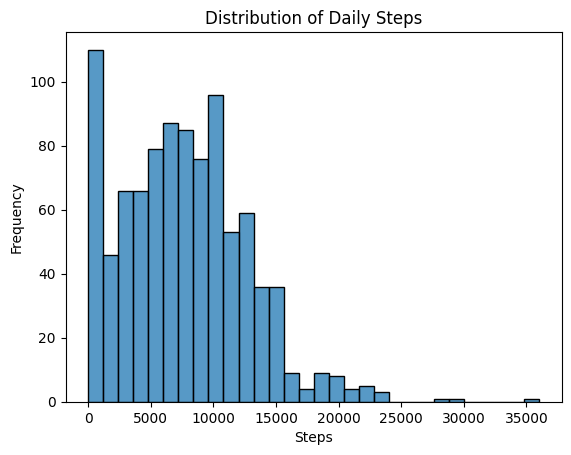

In [6]:
plt.figure()

sns.histplot(daily_activity["TotalSteps"], bins=30)

plt.title("Distribution of Daily Steps")
plt.xlabel("Steps")
plt.ylabel("Frequency")

plt.show()

### Calories vs Steps

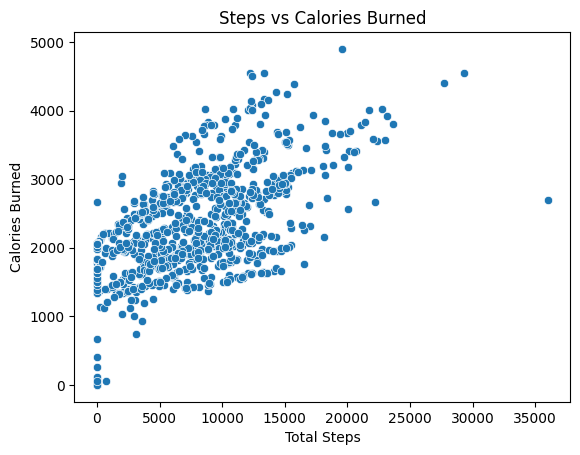

In [7]:
plt.figure()

sns.scatterplot(x="TotalSteps", y="Calories", data=daily_activity)

plt.title("Steps vs Calories Burned")
plt.xlabel("Total Steps")
plt.ylabel("Calories Burned")

plt.show()

### Activity Minutes Comparison

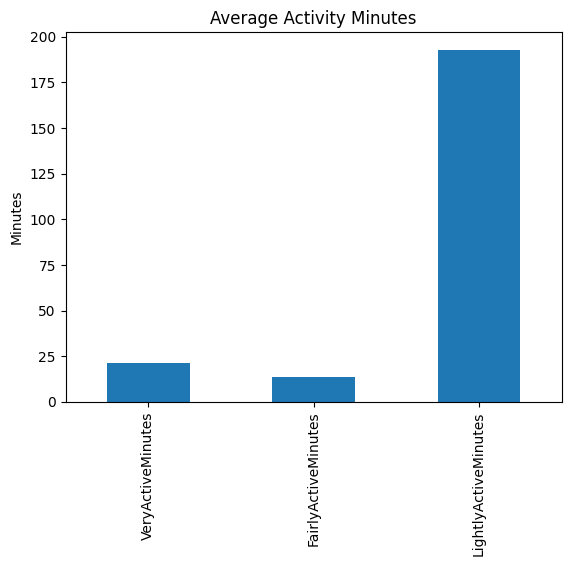

In [8]:
activity_minutes = daily_activity[
    ["VeryActiveMinutes","FairlyActiveMinutes","LightlyActiveMinutes"]
].mean()

plt.figure()

activity_minutes.plot(kind="bar")

plt.title("Average Activity Minutes")
plt.ylabel("Minutes")

plt.show()

### Sleep Duration

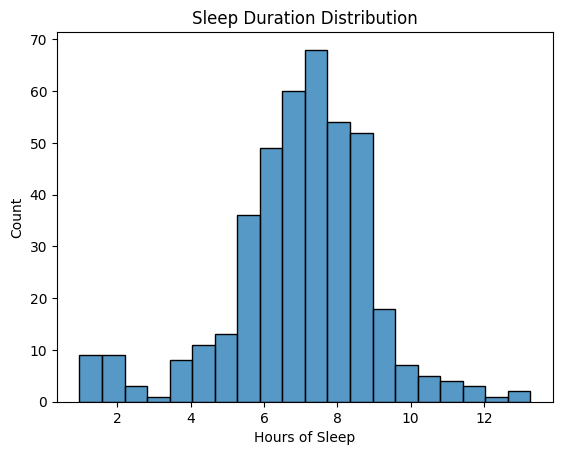

In [9]:
sleep_day["SleepHours"] = sleep_day["TotalMinutesAsleep"] / 60

plt.figure()

sns.histplot(sleep_day["SleepHours"], bins=20)

plt.title("Sleep Duration Distribution")
plt.xlabel("Hours of Sleep")

plt.show()

### Most Active Hours

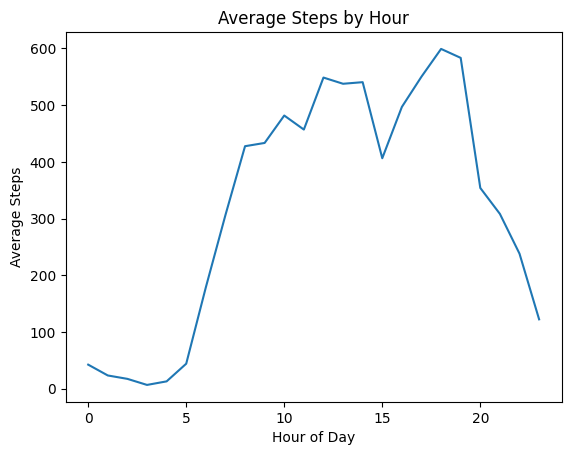

In [10]:
hourly_steps["Hour"] = hourly_steps["ActivityHour"].dt.hour

hourly_activity = hourly_steps.groupby("Hour")["StepTotal"].mean()

plt.figure()

hourly_activity.plot(kind="line")

plt.title("Average Steps by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Steps")

plt.show()

### Calories Burn Pattern

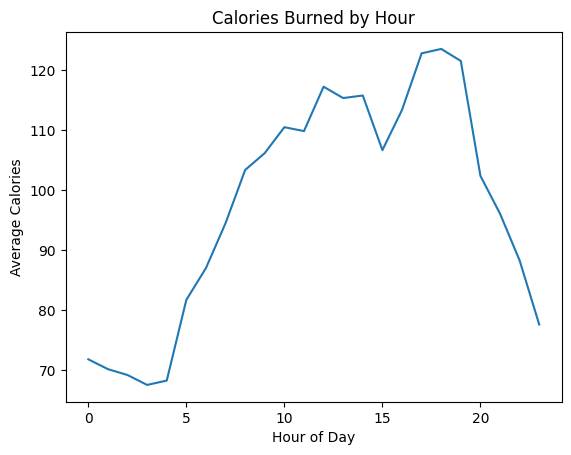

In [11]:
hourly_calories["Hour"] = hourly_calories["ActivityHour"].dt.hour

hourly_cal = hourly_calories.groupby("Hour")["Calories"].mean()

plt.figure()

hourly_cal.plot(kind="line")

plt.title("Calories Burned by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Calories")

plt.show()

### Correlation Heatmap

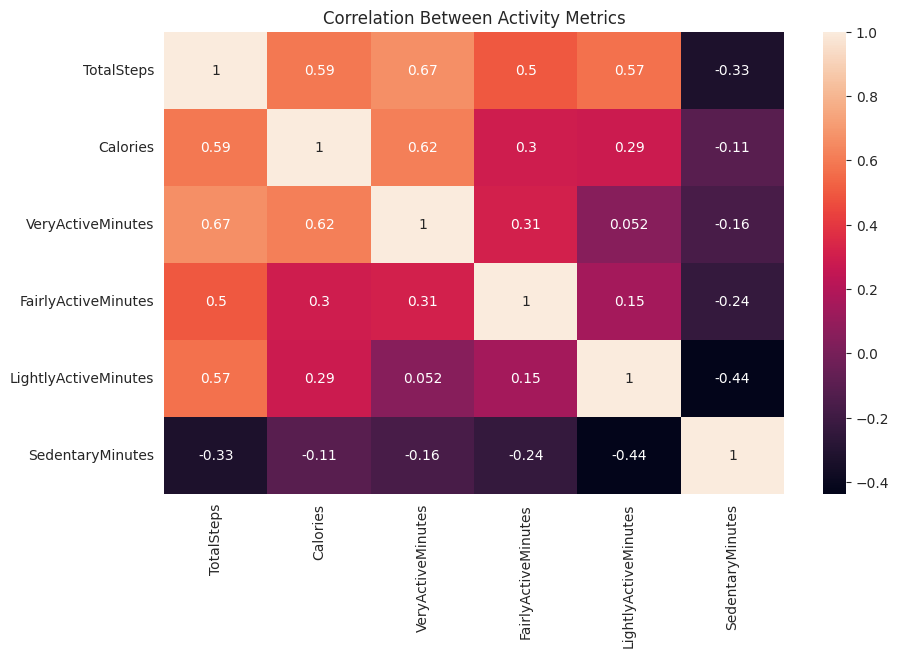

In [14]:
plt.figure(figsize=(10,6))

corr = daily_activity[
[
"TotalSteps",
"Calories",
"VeryActiveMinutes",
"FairlyActiveMinutes",
"LightlyActiveMinutes",
"SedentaryMinutes"
]
].corr()

sns.heatmap(corr, annot=True)

plt.title("Correlation Between Activity Metrics")

plt.show()

### User Activity Segmentation

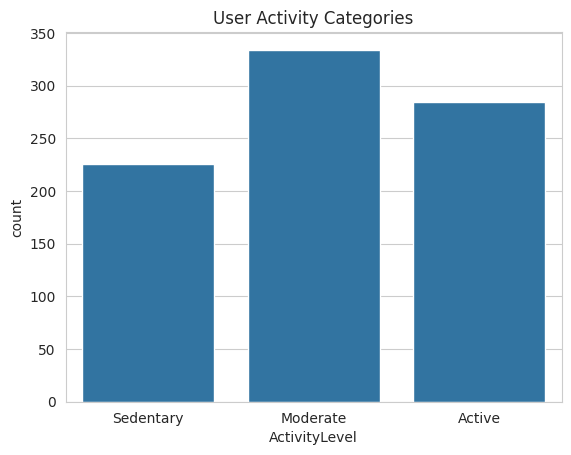

In [15]:
daily_activity["ActivityLevel"] = pd.cut(
daily_activity["TotalSteps"],
bins=[0,5000,10000,20000],
labels=["Sedentary","Moderate","Active"]
)
plt.figure()

sns.countplot(x="ActivityLevel", data=daily_activity)

plt.title("User Activity Categories")

plt.show()